# Predicting car prices

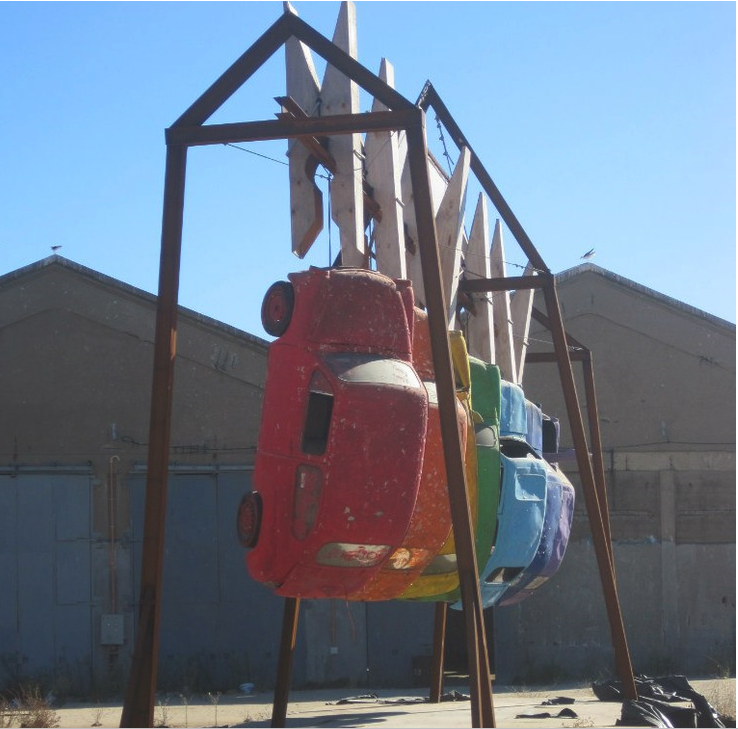

## Project Aim

The aim of this project is to develop a model that uses a number of features of various cars to make a prediction about the price of car of interest. The cars being considered in this project were available to the US import market in 1985.

This project forms part of an ongoing Data Science course and is also aimed at gaining experience in the use of the K-Nearest Neighbour algorithm, as implemented by the scikit-learn python library.

## Dataset

The dataset used is an abstract from the 1985 Ward's Automotive Yearbook and is available as csv file. Information about the dataset can be found [here](https://archive.ics.uci.edu/ml/datasets/automobile)



## Importing Data

In [22]:
# set up our working environment
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import operator
import seaborn as sns
import sklearn
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score, KFold


In [2]:
imports = pd.read_csv('imports-85.data', header=None)
imports.columns=['symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration', 'num_of_doors', 'body_style', 'drive_wheels', 'engine_location', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_type', 'num_of_cylinder', 'engine_size', 'fuel_system', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg', 'price']
imports.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_of_doors       205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_of_cylinder    205 non-null    object 
 16  engine_size        205 non

In [3]:
imports.head()


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


## Data Set Information

This data set consists of three types of entities: 

(a) the specification of an auto in terms of various characteristics 
(b) its assigned insurance risk rating
(c) its normalized losses in use as compared to other cars. 

The second rating corresponds to the degree to which the auto is more risky than its price indicates. Cars are initially assigned a risk factor symbol associated with its price. Then, if it is more risky (or less), this symbol is adjusted by moving it up (or down) the scale. Actuarians call this process "symboling". A value of +3 indicates that the auto is risky, -3 that it is probably pretty safe.

The third factor is the relative average loss payment per insured vehicle year. This value is normalized for all autos within a particular size classification (two-door small, station wagons, sports/speciality, etc...), and represents the average loss per car per year.

### Attribute Information: Attribute: Attribute Range

1. symboling: -3, -2, -1, 0, 1, 2, 3.
2. normalized-losses: continuous from 65 to 256.
3. make: alfa-romero, audi, bmw, chevrolet, dodge, honda, isuzu, jaguar, mazda, mercedes-benz, mercury, mitsubishi, nissan, peugot, plymouth, porsche, renault, saab, subaru, toyota, volkswagen, volvo
4. fuel-type: diesel, gas.
5. aspiration: std, turbo.
6. num-of-doors: four, two.
7. body-style: hardtop, wagon, sedan, hatchback, convertible.
8. drive-wheels: 4wd, fwd, rwd.
9. engine-location: front, rear.
10. wheel-base: continuous from 86.6 to 120.9.
11. length: continuous from 141.1 to 208.1.
12. width: continuous from 60.3 to 72.3.
13. height: continuous from 47.8 to 59.8.
14. curb-weight: continuous from 1488 to 4066.
15. engine-type: dohc, dohcv, l, ohc, ohcf, ohcv, rotor.
16. num-of-cylinders: eight, five, four, six, three, twelve, two.
17. engine-size: continuous from 61 to 326.
18. fuel-system: 1bbl, 2bbl, 4bbl, idi, mfi, mpfi, spdi, spfi.
19. bore: continuous from 2.54 to 3.94.
20. stroke: continuous from 2.07 to 4.17.
21. compression-ratio: continuous from 7 to 23.
22. horsepower: continuous from 48 to 288.
23. peak-rpm: continuous from 4150 to 6600.
24. city-mpg: continuous from 13 to 49.
25. highway-mpg: continuous from 16 to 54.
26. price: continuous from 5118 to 45400.

## Potential feature columns

The columns available for using as features - which must be continuous numeric columns - are as stated below:

* symboling 205 non-null int64
* normalized_losses 205 non-null object
* wheel_base 205 non-null float64
* length 205 non-null float64
* width 205 non-null float64
* height 205 non-null float64
* curb_weight 205 non-null int64
* engine_size 205 non-null int64
* bore 205 non-null object
* stroke 205 non-null object
* compression_ratio 205 non-null float64
* horsepower 205 non-null object
* peak_rpm 205 non-null object
* city_mpg 205 non-null int64
* highway_mpg 205 non-null int64
* price 205 non-null object

The reason that some of these columns are not currently showing as numeric types is likely to be due to those columns containing some 'Null' values which are shown as'?' in this dataset. These will need to be replaced with np.nan.

### Target Column

The target column for this analysis will be the 'price' column

## Exploring the numeric columns

In [4]:
# Select only the columns with continuous values
continuous_values = ['normalized_losses', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_size', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg', 'price']
numeric_imports = imports[continuous_values]

In [5]:
numeric_imports


,normalized_losses,wheel_base,length,width,height,curb_weight,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,?,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495
1,?,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500
2,?,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,16500
3,164,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,13950
4,164,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,95,109.1,188.8,68.9,55.5,2952,141,3.78,3.15,9.5,114,5400,23,28,16845
201,95,109.1,188.8,68.8,55.5,3049,141,3.78,3.15,8.7,160,5300,19,25,19045
202,95,109.1,188.8,68.9,55.5,3012,173,3.58,2.87,8.8,134,5500,18,23,21485
203,95,109.1,188.8,68.9,55.5,3217,145,3.01,3.40,23.0,106,4800,26,27,22470


## Data cleaning

We need to set the '?' values, used in the dataset to numpy.nan values, so that analysis is possible. Also, with 'price' being the target column, we need values in all rows and will therefore delete any rows missing 'price' values.

In [6]:
numeric_imports = numeric_imports.replace('?', np.nan)
numeric_imports.head(5)

,normalized_losses,wheel_base,length,width,height,curb_weight,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,NaN,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495
1,NaN,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500
2,NaN,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,16500
3,164,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,13950
4,164,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,17450


In [7]:
numeric_imports = numeric_imports.astype('float')
numeric_imports.isnull().sum()

normalized_losses    41
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_size           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 4
dtype: int64

In [8]:
# Dealing with empty 'price' values
numeric_imports = numeric_imports.dropna(subset=['price'])
numeric_imports.isnull().sum()

normalized_losses    37
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_size           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 0
dtype: int64

### Dealing with the the 'normalized_losses' column

With 37 nan's in this column, accounting for nearly 20% of all rows, I have decided that the use of the mean value would significantly impact on possible results if this column was used. We will therefore drop this column from the dataset.

In [9]:
numeric_imports = numeric_imports.drop('normalized_losses', axis = 1)
numeric_imports.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 201 entries, 0 to 204
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   wheel_base         201 non-null    float64
 1   length             201 non-null    float64
 2   width              201 non-null    float64
 3   height             201 non-null    float64
 4   curb_weight        201 non-null    float64
 5   engine_size        201 non-null    float64
 6   bore               197 non-null    float64
 7   stroke             197 non-null    float64
 8   compression_ratio  201 non-null    float64
 9   horsepower         199 non-null    float64
 10  peak_rpm           199 non-null    float64
 11  city_mpg           201 non-null    float64
 12  highway_mpg        201 non-null    float64
 13  price              201 non-null    float64
dtypes: float64(14)
memory usage: 23.6 KB


### Dealing with the remaining null values

For the remaining entries we shall replace any null values with the mean value for the relevant column.

In [10]:
# Replace all remaining missing values in other columns using column means.
numeric_imports = numeric_imports.fillna(numeric_imports.mean())
numeric_imports.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 201 entries, 0 to 204
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   wheel_base         201 non-null    float64
 1   length             201 non-null    float64
 2   width              201 non-null    float64
 3   height             201 non-null    float64
 4   curb_weight        201 non-null    float64
 5   engine_size        201 non-null    float64
 6   bore               201 non-null    float64
 7   stroke             201 non-null    float64
 8   compression_ratio  201 non-null    float64
 9   horsepower         201 non-null    float64
 10  peak_rpm           201 non-null    float64
 11  city_mpg           201 non-null    float64
 12  highway_mpg        201 non-null    float64
 13  price              201 non-null    float64
dtypes: float64(14)
memory usage: 23.6 KB


## Normalizing the feature columns

Having cleaned all of the potential features of interest, we need to normalise all these columns so that they each do not have an overly significant impact on the analysis.

An excellent article, that summarises the various normalization techniques, can be found [here](https://analystanswers.com/data-normalization-techniques-easy-to-advanced-the-best/) 

The method we shall use for this analysis is the Linear Normalization technique, also known as 'Max-Min'.

In [11]:
# normalize all columns
normalized_imports = (numeric_imports - numeric_imports.min())/(numeric_imports.max() - numeric_imports.min())
# and now return the 'price' column to its original figures
normalized_imports['price'] = numeric_imports['price']
# and view the results
normalized_imports.head()

,wheel_base,length,width,height,curb_weight,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,0.058309,0.413433,0.324786,0.083333,0.411171,0.260377,0.664286,0.290476,0.1250,0.294393,0.346939,0.222222,0.289474,13495.0
1,0.058309,0.413433,0.324786,0.083333,0.411171,0.260377,0.664286,0.290476,0.1250,0.294393,0.346939,0.222222,0.289474,16500.0
2,0.230321,0.449254,0.444444,0.383333,0.517843,0.343396,0.100000,0.666667,0.1250,0.495327,0.346939,0.166667,0.263158,16500.0
3,0.384840,0.529851,0.504274,0.541667,0.329325,0.181132,0.464286,0.633333,0.1875,0.252336,0.551020,0.305556,0.368421,13950.0
4,0.373178,0.529851,0.521368,0.541667,0.518231,0.283019,0.464286,0.633333,0.0625,0.313084,0.551020,0.138889,0.157895,17450.0


In [16]:
normalized_imports.applymap(lambda x: isinstance(x, (int, float))).sum()

wheel_base           201
length               201
width                201
height               201
curb_weight          201
engine_size          201
bore                 201
stroke               201
compression_ratio    201
horsepower           201
peak_rpm             201
city_mpg             201
highway_mpg          201
price                201
dtype: int64

## Data analysis

We are now ready to start our analysis of the various features to determine which give best performance in any model.

We start with some univariate k-nearest neighbors models. Starting with simple models before moving to more complex models helps to structure the code workflow and understand the features better

### Pearson Correlation

Let us first of all simply look at the Pearson Correlation between all of the features, to see if there are any likely dependencies between any of the features and then we can try to identify any likely candidates for our model based on their correlations with the 'price' target.

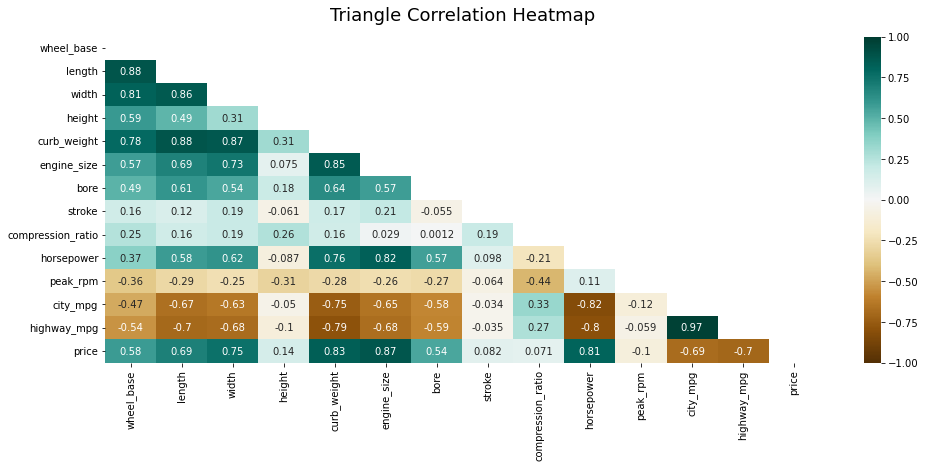

In [12]:
plt.figure(figsize=(16, 6))
# define the mask to set the values in the upper triangle to True
mask = np.triu(np.ones_like(normalized_imports.corr(), dtype= bool))
heatmap = sns.heatmap(normalized_imports.corr(), mask=mask, vmin=-1, vmax=1, annot=True, cmap='BrBG')
heatmap.set_title('Triangle Correlation Heatmap', fontdict={'fontsize':18}, pad=16);

We can see some obvious connections between certain features in the dataset. For example:

* city_mpg and highway_mpg
* wheel_base, length, width and curb_weight

If we included a number of these related features in our model, that interrelationship could bias our model towards these features, so we do need to be mindful of this.

Now let's look at any correlations between all of the features and the 'price' target.

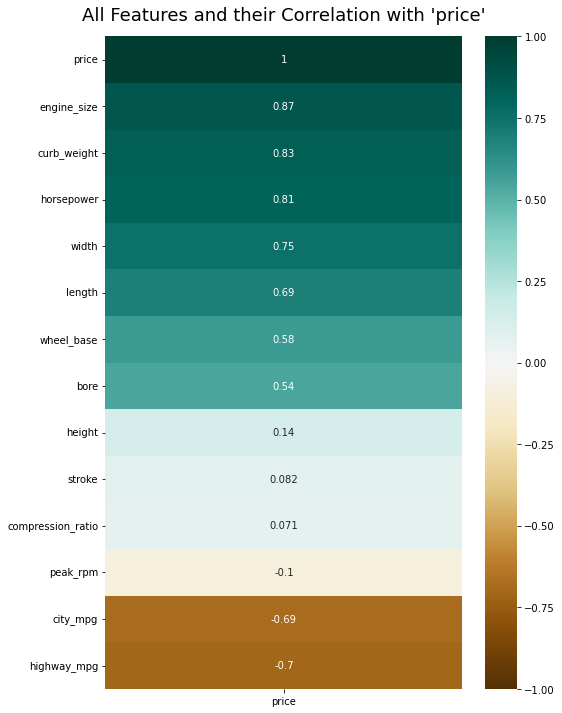

In [13]:
plt.figure(figsize=(8, 12))
heatmap = sns.heatmap(normalized_imports.corr()[['price']].sort_values(by='price', ascending=False), vmin=-1, vmax=1, annot=True, cmap='BrBG')
heatmap.set_title("All Features and their Correlation with 'price'", fontdict={'fontsize':18}, pad=16);

The graph above shows there are relatively strong positive correlations between 'price' and:

* engine_size
* curb_weight
* horsepower

Whereas there are relatively strong negative correlations between 'price' and the economic factors of:

* highway_mpg
* city_mpg

## Using the scikit-learn's KNeighborsRegressor to identify candidate features

To further explore the possible candidates for inclusion in the model we shall scikit-learn's KNeighborsRegressor algorithm to do an inital assessment of the results obtained for all features. Initially, we shall use the algorithm's default parameter settings, apart from stipulating the algorithm uses the 'Brute Force' method is used, which is suitable for small samples such as the dataset that we are working with here. We will simply split the dataset into two halves: 50% as the training set and 50% as the test set. We shall use Root Mean Square Error (RMSE) obtained for each feature as the performance score.

In [30]:
def knn_train_test(train_cols, target_col, df, k=5):
    '''Takes in a train column/columns, the target column, the dataframe, and the number of 
    the nearest neighbors. 
    Trains and tests the model using test/train validation approach. 
    Returns RMSE value.
    '''
    
    # One-column case
    if type(train_cols)==str:
        X_train, X_test, y_train, y_test = train_test_split(df[[train_cols]], df[target_col],
                                                            test_size=0.5, random_state=1)
    # Multi-column case
    elif type(train_cols)==list:
        X_train, X_test, y_train, y_test = train_test_split(df[train_cols], df[target_col],
                                                            test_size=0.5, random_state=1)
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    predictions = knn.predict(X_test)
    mse = mean_squared_error(y_test, predictions)
    return mse**(0.5)

rmse_default_k = {}

# Isolating all the numeric columns except for `price` as train columns
train_cols = normalized_imports.columns.drop('price')

# Creating a univariate model for each column using the default value of k and adding each RMSE
# to the dictionary
for col in train_cols:
    rmse = knn_train_test(col, 'price', normalized_imports)
    rmse_default_k[col] = round(rmse)

# Sorting the dictionary by RMSE in ascending order
sorted_rmse_default_k = dict(sorted(rmse_default_k.items(), key=operator.itemgetter(1)))
rmse_results_series = pd.Series(sorted_rmse_default_k)
rmse_results_series.sort_values()

engine_size          3538
curb_weight          3826
horsepower           3938
width                4281
highway_mpg          4421
city_mpg             4478
length               5799
wheel_base           5807
compression_ratio    6235
bore                 6645
stroke               7607
height               7927
peak_rpm             8130
dtype: int64

### Results from using the standard settings

Using the default number of neighbors (k=5). Engine_size' (RMSE 3538) is significantly better than the other features, with 'curb_weight' (RMSE 3826) also fairly good and the following by horsepower (RMSE 3938) and 3 features, down to 'city_mpg' giving similar results (RMSE's of 4281 to 4478).

## Exploring how varying the k-value, used in the KNeighborsRegressor, impacts on the results obtained


We shall now run the same exercise, but this time we shall vary the k-value to see what the optimum k-value should be. We shall use k-values between 1 and 9, and then visualise the results using a line graph.

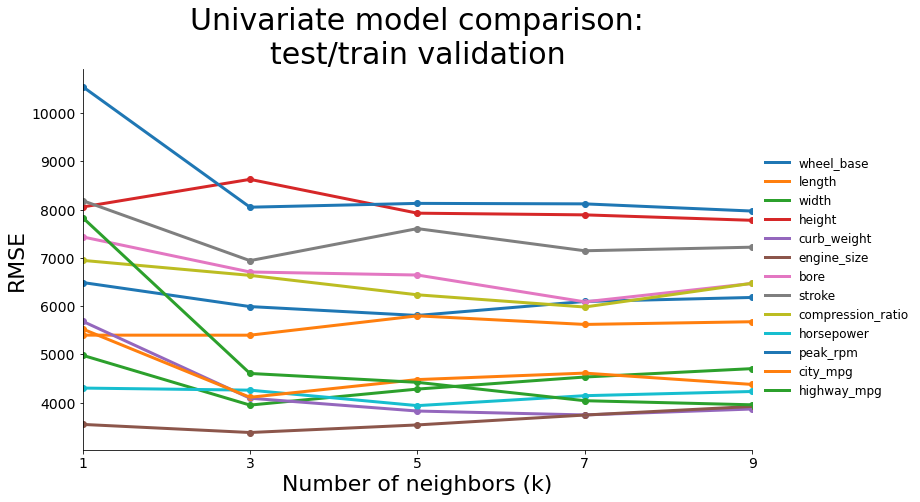

In [31]:
rmse_various_k = {}

plt.figure(figsize=(12,7))

# Creating univariate models for each column with various values of k, adding each RMSE 
# to the dictionary, and plotting the results for all variables
for col in train_cols:
    rmse_various_k[col] = []
    for k in [1, 3, 5, 7, 9]:
        rmse = knn_train_test(col, 'price', normalized_imports, k)
        rmse_various_k[col].append(round(rmse))
    plt.scatter(list(range(1,10, 2)), rmse_various_k[col])
    plt.plot(list(range(1,10, 2)), rmse_various_k[col], linewidth=3)
plt.title('Univariate model comparison:\ntest/train validation', fontsize=30)
plt.xlabel('Number of neighbors (k)', fontsize=22)
plt.ylabel('RMSE', fontsize=22)
plt.xticks([1,3,5,7,9], fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(1,9)
plt.legend(train_cols, frameon=False, bbox_to_anchor=(1.25, 0.8), fontsize=12)
sns.despine()
plt.show()

From the "spaghetti chart" above, we clearly see that among all the univariate models, the ones with the engine-size column performed the best again, with any k value from our selection. For k=1, though, it demonstrates even lower RMSE than in the previous case (k=5). The difference, however, isn't considerable:

In [33]:
k_1 = rmse_various_k['engine_size'][0]
k_5 = rmse_various_k['engine_size'][2]
print(f'\033[1mRMSE for the univariate models with `engine-size`:\033[0m'
      f'\nk=1: {k_1}'
      f'\nk=5: {k_5}')

RMSE for the univariate models with `engine-size`:
k=1: 3549
k=5: 3538


## Creating Multivariate Models

Next, let's create some multivariate models. First, we're going to try different combinations of the best features (with the lowest average RMSE) from the previous step to train and test a multivariate KNN model using the default k value (k=5): 2, 3, 4, and 5 best features:

In [35]:
rmse_various_k_mean = {}

# Finding the mean value of RMSE for each variable
for key in rmse_various_k:
    rmse_various_k_mean[key] = np.mean(rmse_various_k[key])

# Sorting the dictionary by RMSE in ascending order
sorted_rmse_various_k_mean = dict(sorted(rmse_various_k_mean.items(), key=operator.itemgetter(1)))
sorted_rmse_various_k_mean_series =  pd.Series(sorted_rmse_various_k_mean)
sorted_rmse_various_k_mean_series.sort_values()

engine_size          3626.4
horsepower           4174.8
curb_weight          4243.6
width                4489.6
city_mpg             4621.0
highway_mpg          4971.6
length               5578.8
wheel_base           6113.0
compression_ratio    6455.6
bore                 6669.8
stroke               7421.6
height               8056.2
peak_rpm             8564.6
dtype: float64

The 5 best features are: ```engine_size```, ```horsepower```,```curb_weight```, ```width```,  ```city_mpg```. Hence, we have to consider the following combinations:

* ```engine_size```, ```horsepower```
* ```engine_size```, ```horsepower```, ```curb_weight```
* ```engine_size```, ```horsepower```, ```curb_weight```, ```width```
* ```engine_size```, ```horsepower```,```curb_weight```, ```width```,  ```city_mpg```

In [37]:
rmse_multivariate = []

for i in [2,3,4,5]:
    
    # Selecting from 2 to 5 best features
    train_cols_list = list(sorted_rmse_various_k_mean.keys())[:i]
    
    # Creating a multivariate model for each combination of features using the default k=5 
    # and rounding the resulting RMSE
    rmse = round(knn_train_test(train_cols_list, 'price', normalized_imports))
    
    # Appending the RMSE value of each multivariate model to the list
    rmse_multivariate.append(rmse)
        
rmse_multivariate

[3607, 3398, 3361, 3426]

The TOP3 models with the lowest RMSE from the previous step are:

1. With 4 best features ( ```engine_size```, ```horsepower```, ```curb_weight```, ```width```
) and RMSE=3361.
2. With 3 best features (```engine_size```, ```horsepower```, ```curb_weight```) and RMSE=3398.
3. With 5 best features (```engine_size```, ```horsepower```,```curb_weight```, ```width```,  ```city_mpg```) and RMSE=3426.

As we did for the univariate models, let's tune the hyperparameter k for each of these TOP3 models and observe the results:



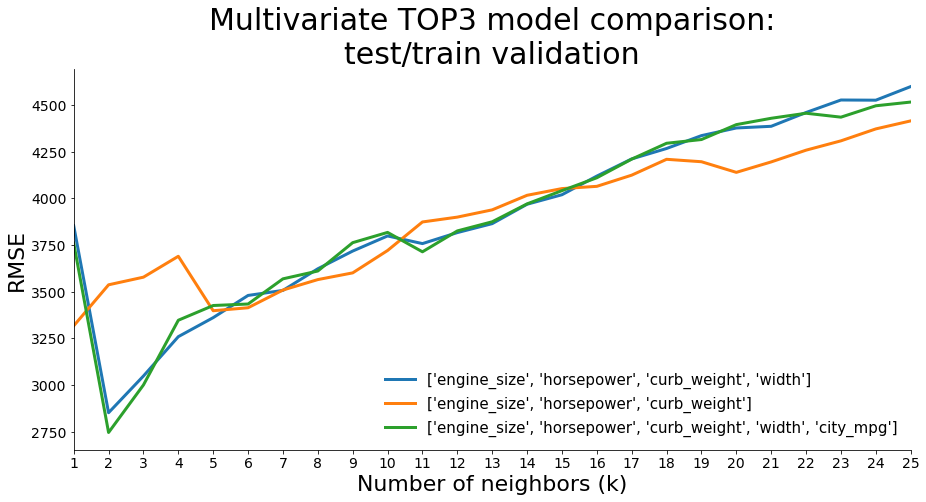

In [38]:
train_cols_list = [['engine_size', 'horsepower', 'curb_weight', 'width'],
                   ['engine_size', 'horsepower', 'curb_weight'],
                   ['engine_size', 'horsepower', 'curb_weight', 'width', 'city_mpg']]
rmse_multivar_various_k = {}

plt.figure(figsize=(15,7))

# Creating multivariate models for each feature combination with k from 1 to 25, adding each RMSE
# to the dictionary, and plotting the results for all the models
for ind, lst in enumerate(train_cols_list):
    rmse_multivar_various_k[ind+1] = []
    for k in list(range(1,26)):
        rmse = knn_train_test(lst, 'price', normalized_imports, k)
        rmse_multivar_various_k[ind+1].append(round(rmse))
    plt.plot(list(range(1,26)), rmse_multivar_various_k[ind+1], linewidth=3)
plt.title('Multivariate TOP3 model comparison:\ntest/train validation', fontsize=30)
plt.xlabel('Number of neighbors (k)', fontsize=22)
plt.ylabel('RMSE', fontsize=22)
plt.xlim(1,25)
plt.xticks(list(range(1,26)), fontsize=14)
plt.yticks(fontsize=14)
plt.legend(train_cols_list, frameon=False, loc=4, bbox_to_anchor=None, fontsize=15)
sns.despine()
plt.show()

#### Observations

The 4-feature model and the 5 feature model have good perfomrance with the optimal number of neighbors k equal to 2. Then, it starts constantly increasing. 


#### Minimum value of RMSE:

In [49]:
feature4model = np.min(rmse_multivar_various_k[1])
print(f'4 feature model minumum value of RMSE:{feature4model}')

4 feature model minumum value of RMSE:2851


In [51]:
feature5model = np.min(rmse_multivar_various_k[3])
print(f'5 feature model minumum value of RMSE:{feature5model}')

5 feature model minumum value of RMSE:2745


In [50]:
feature3model = np.min(rmse_multivar_various_k[2])
print(f'3 feature model minumum value of RMSE:{feature3model}')

3 feature model minumum value of RMSE:3317


For the 3-feature models, the lowest value of error is 15% and 18% higher than the 4 feature and 5 feature model respectively and it is related to k=1. For higher values of k, the RMSE is constantly increasing.

In practice, considering too few neighbors (i.e. too small values of k) implies a high impact of noise on the result. Instead, considering too many neighbors results in involving irrelevant neighbors from other clusters (and indeed, for higher values of k, the error is constantly increasing).

Since our goal is to select the model with the smallest error and, hence, the highest predictive capacity for the car price, let's review our best results so far:

* ***Univariate models:***
    * Default k=5: ```engine_size``` (RMSE=3538)
    * Optimal k=1: ```engine_size``` (RMSE=3549)
    
* ***Multivariate models:***
    * Default k=5: ```engine_size```, ```horsepower```, ```curb_weight```, ```width``` (RMSE=3361).
    * Optimal k=2 ```engine_size```, ```horsepower```, ```curb_weight```, ```width``` (RMSE=2851).

The difference between all the RMSE is slightly considerable. The lowest RMSE is related to the multivariate model with engine-size and k=2. However, as we mentioned earlier, considering too few nearest neighbors leads to noise influence. Hence, a safer choice is the second best multivariate model with ```engine_size```, ```horsepower```, ```curb_weight```, ```width``` (RMSE=3361).

## K-Fold Cross-Validation

### Creating Univariate Models

Now, we'll create univariate KNN models using k-fold cross-validation approach. This time, we won't vary the number of the nearest neighbors leaving it equal to the default value k=5 ***(where k is the number of the nearest neighbors, not the number of folds)***. Instead, let's vary the number of folds and visualize the results:



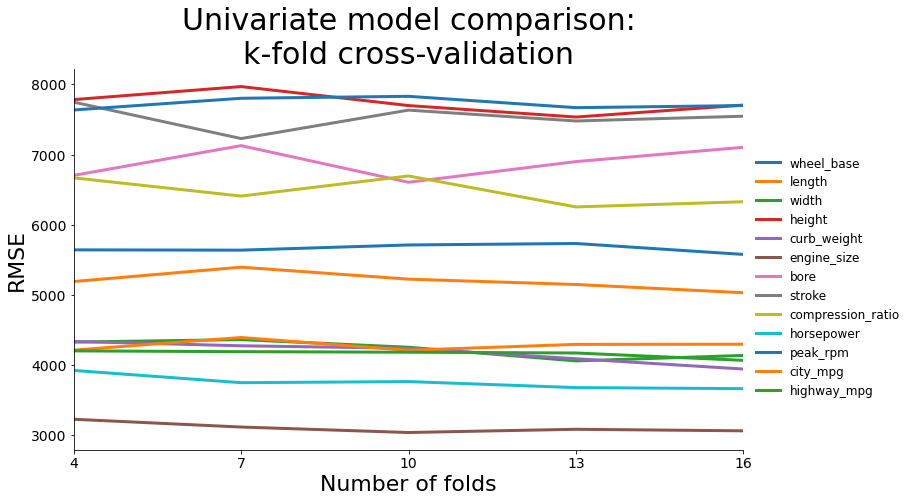

engine_size          3099.4
horsepower           3750.2
highway_mpg          4158.0
curb_weight          4171.6
width                4223.2
city_mpg             4276.8
length               5194.4
wheel_base           5657.4
compression_ratio    6469.2
bore                 6887.0
stroke               7527.2
peak_rpm             7727.6
height               7738.8
dtype: float64

In [53]:
def k_fold_cross_val(n_splits, train_cols, target_col, df, k=5):
    '''Takes in the number/numbers of folds as an integer or a list correspondingly, a train
    column/columns, the target column, the dataframe, and the number of the nearest neighbors.
    Trains and tests the model using k-fold cross-validation approach. 
    Returns RMSE value.
    '''
    
    # One number of folds
    if type(n_splits)==int:
        kf = KFold(n_splits, shuffle=True, random_state=1)
        knn = KNeighborsRegressor(n_neighbors=k)
        
        # One-column case
        if type(train_cols)==str:
            mses = cross_val_score(knn, df[[train_cols]], df['price'],
                                   scoring='neg_mean_squared_error', cv=kf)
        
        # Multi-column case
        elif type(train_cols)==list:
            mses = cross_val_score(knn, df[train_cols], df['price'],
                                   scoring='neg_mean_squared_error', cv=kf)
        return np.mean(abs(mses)**0.5)
    
    # Several numbers of folds
    if type(n_splits)==list:
        for n in n_splits:
            kf = KFold(n, shuffle=True, random_state=1)
            knn = KNeighborsRegressor(n_neighbors=k)
            
            # One-column case
            if type(train_cols)==str:
                mses = cross_val_score(knn, df[[train_cols]], df['price'], 
                                       scoring='neg_mean_squared_error', cv=kf)
                
            # Multi-column case
            elif type(train_cols)==list:
                mses = cross_val_score(knn, df[train_cols], df['price'], 
                                       scoring='neg_mean_squared_error', cv=kf)
            rmses = np.sqrt(np.absolute(mses))
            avg_rmse = np.mean(rmses)
            std_rmse = np.std(rmses)
            print(f'{n} folds: \navg_RMSE={round(avg_rmse)}, std_RMSE={round(std_rmse)}')            
            
rmse_kfold_univar = {}

plt.figure(figsize=(12,7))

# Creating univariate models for each column using k-fold cross-validation, the default k and 
# various numbers of folds, adding each RMSE to the dictionary, and plotting the results
for col in train_cols:
    rmse_kfold_univar[col] = []
    for n in [4, 7, 10, 13, 16]:
        rmse = k_fold_cross_val(n, col, 'price', normalized_imports)
        rmse_kfold_univar[col].append(round(rmse))
    plt.plot(list(range(4,17, 3)), rmse_kfold_univar[col], linewidth=3)
plt.title('Univariate model comparison:\nk-fold cross-validation', fontsize=30)
plt.xlabel('Number of folds', fontsize=22)
plt.ylabel('RMSE', fontsize=22)
plt.xticks([4, 7, 10, 13, 16], fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(4,16)
plt.legend(train_cols, frameon=False, bbox_to_anchor=(1.25, 0.8), fontsize=12)
sns.despine()
plt.show()

rmse_kfold_univar_mean = {}

# Finding the mean value of RMSE for each variable
for key in rmse_kfold_univar:
    rmse_kfold_univar_mean[key] = np.mean(rmse_kfold_univar[key])

# Sorting the dictionary by RMSE in ascending order
sorted_rmse_kfold_univar_mean = dict(sorted(rmse_kfold_univar_mean.items(), key=operator.itemgetter(1)))
sorted_rmse_kfold_univar_mean__series = pd.Series(sorted_rmse_kfold_univar_mean)
sorted_rmse_kfold_univar_mean__series.sort_values()

Both from the "spaghetti chart" and the mean values of RMSE for each variable, we deduce once again that the univariate model with the engine_size column demonstrates the lowest RMSE with any number of folds from our selection (the minimum error with the number of folds equal to 13) and, hence, performs best of all for predicting car prices.



### Creating Multivariate Models

Let's now create some multivariate models. We'll apply the following algorithm:

* Select 5 best features from the previous step: engine_size, horsepower, highway_mpg, curb_weight, and width.
* Try different combinations of them: 2, 3, 4, and 5 best features:
    * engine_size, horsepower
    * engine_size, horsepower, highway_mpg
    * engine_size, horsepower, highway_mpg, curb_weight
    * engine_size, horsepower, highway_mpg, curb_weight, and width
  
* Vary the number of folds (the same selection as we used for the univariate models: 4, 7, 10, 13, 16).
* Vary the number of the nearest neighbors from 3 to 10.

* Train and test a multivariate KNN model for each combination of features, using different numbers of folds and nearest neighbors.
* Visualize the results (each figure will represent all 4 combinations of features, with all the options of the fold numbers from the selection and a fixed number of the nearest neighbors).

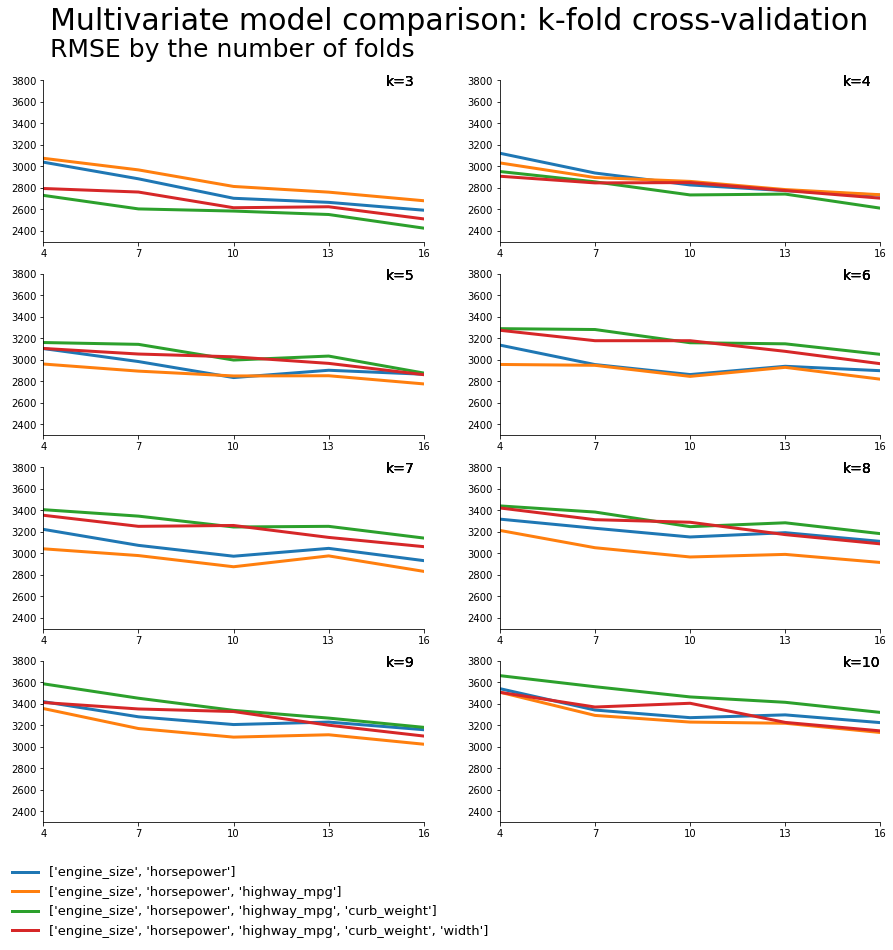

In [67]:
train_cols_list = [['engine_size', 'horsepower'],
                   ['engine_size', 'horsepower', 'highway_mpg'],
                   ['engine_size', 'horsepower', 'highway_mpg', 'curb_weight'],
                   ['engine_size', 'horsepower', 'highway_mpg', 'curb_weight', 'width']]
rmse_kfold_multivar = {}

plt.figure(figsize=(15,35))

# Creating multivariate models for each feature combination using k-fold cross-validation,
# various numbers of folds and the nearest neighbors, adding each RMSE to the dictionary,
# and plotting the results
for k in range(3,11):
    plt.subplot(10, 2, k-2)
    for ind, lst in enumerate(train_cols_list):
        rmse_kfold_multivar[ind+1] = []
        for n in [4, 7, 10, 13, 16]:
            rmse = k_fold_cross_val(n, lst, 'price', normalized_imports, k)
            rmse_kfold_multivar[ind+1].append(round(rmse))
        plt.plot([4, 7, 10, 13, 16], rmse_kfold_multivar[ind+1], linewidth=3)
        plt.text(14.8, 3750, f'k={k}', fontsize=14)
    if k==10:
        plt.legend(train_cols_list, frameon=False, bbox_to_anchor=(0,-0.2), fontsize=13)
        plt.text(-10.2, 9670,'Multivariate model comparison: k-fold cross-validation', fontsize=30)
        plt.text(-10.2, 9420,'RMSE by the number of folds', fontsize=25)
    plt.xticks([4, 7, 10, 13, 16], fontsize=10)
    plt.yticks(fontsize=10)
    plt.ylim(2300,3800)
    plt.xlim(4,16)
    sns.despine()
plt.show()

### Observations

* Increasing the number of folds leads to decreasing the error of price prediction ***on the test set** for all the models. It's explainable: in this case, we overfit the model. However, such a model can demonstrate poor performance on completely new data.
* Increasing the number of the nearest neighbors leads, in the longer term, to the increase of the error of price prediction (because of involving irrelevant neighbors). It's especially evident for the models with more features that are more sensitive to the changes of k. To reduce the error, keeping at the same time as many features for price prediction as reasonably possible, we have to consider relatively low k values.
* It's important to remember that we have a small sample in our dataset only 205 entries. To avoid model overfitting, we'd better consider relatively low values of the number of folds.

Hence, the ***model with the 4 best features (engine_size, horsepower, highway_mpg, curb_weight), 10 folds, and 4 nearest neighbors*** is an good candidate. Indeed, of all the models we created so far, this one has the lowest RMSE value, while still having reasonable values of the number of folds and the nearest neighbors

In [69]:
# Calculation the RMSE value of the model that performed best of all
rmse = round(k_fold_cross_val(10, ['engine_size', 'horsepower', 'highway_mpg', 'curb_weight'], 'price', normalized_imports, 4))
print(f'\033[1mRMSE=\033[0m{rmse}')



RMSE=2735


## Conclusion

In this project, we used the KNN algorithm, in particular test/train validation and k-fold cross-validation, to create uni and multivariate ML models for predicting a car's market price based on its attributes. We tried different features and their combinations, different numbers of folds and the nearest neighbors. The main idea was to reduce the error of prediction on the test data and to ensure model feasibility for future unknown data (by avoiding model overfitting).

As a result, the best predictive capacity for the car price was obtained for a multivariate model with 4 features ```engine_size```, ```horsepower```, ```highway_mpg```, ```curb_weight``` created by applying k-fold cross-validation with 10 folds, and 4 nearest neighbors. Its main advantages are:

* the lowest RMSE value while still having reasonable values of the number of folds and the nearest neighbors,
* using several price-influencing features,
* k-fold cross-validation is less biased than test/train validation since it takes advantage of a larger proportion of the data for training while still iterating through different data subsets.

This model, as well as the others that have demonstrated the lowest error, has engine-size as one of the features. Hence, the engine size is one of the most influencing factors on the car price.